# Auditing temporal locality and spectral controls

Compare a lazy random walk on a circle with a state-permuted version of exactly the same transition matrix. The sensor functions remain fixed. This changes temporal locality relative to observations, not the abstract graph spectrum. An IID transition is a negative control, not an entropy-matched condition.

This notebook checks stationary distributions, transition entropy, spectra, observation roughness, spectral embeddings, and alignment-metric sanity tests. These are construction checks, not evidence that a learned effect exists. No GPU is needed.

In [ ]:
from pathlib import Path
import os, subprocess, sys
REPO_URL = 'https://github.com/AlexM3020/The-Role-of-Dynamical-Structure-in-Cross-Modal-Representation-Learning.git'
REPO_NAME = 'The-Role-of-Dynamical-Structure-in-Cross-Modal-Representation-Learning'
REPO_REF = 'main'  # Use an immutable commit before collecting final results.
candidates = [Path.cwd(), *Path.cwd().parents, Path.cwd() / REPO_NAME]
ROOT = next((p for p in candidates if (p / 'src/dynalign/worlds.py').exists()), None)
if ROOT is None:
    ROOT = Path.cwd() / REPO_NAME
    subprocess.check_call(['git', 'clone', REPO_URL, str(ROOT)])
    subprocess.check_call(['git', '-C', str(ROOT), 'checkout', REPO_REF])
sys.path.insert(0, str(ROOT / 'src'))
try:
    import numpy, scipy, pandas, matplotlib, torch
except ModuleNotFoundError:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', '-e', str(ROOT)])
revision = subprocess.run(['git', '-C', str(ROOT), 'rev-parse', '--short', 'HEAD'], text=True, capture_output=True)
print('Repository:', ROOT)
print('Checkout:', revision.stdout.strip() if revision.returncode == 0 else 'initial local checkout')

Repository: c:\Users\z005abpj\Desktop\The-Role-of-Dynamical-Structure-in-Cross-Modal-Representation-Learning
Checkout: initial local checkout


## Configuration and persistence
Use an even number of states and an even embedding dimension to avoid cutting a repeated cycle eigenvalue block. The embedding gap and mixing gap are different quantities.

Local Colab storage disappears with the VM. Set the output path to mounted durable storage when needed. Kaggle outputs must be retained through a saved version.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dynalign.worlds import transition_family, diagnostics, spectral_embedding, sensor_table, sample_pairs, observe, observation_roughness
from dynalign.metrics import linear_cka, procrustes_test_error, effective_rank
from dynalign.experiments import environment, save_json
N_STATES, DIM, SEED = 32, 4, 17
base = Path('/kaggle/working') if Path('/kaggle/working').exists() else ROOT
OUTPUT_DIR = Path(os.environ.get('DYNALIGN_OUTPUT_DIR', str(base / 'outputs'))) / '01_control_audit'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
save_json(OUTPUT_DIR / 'environment.json', environment())
family, permutation = transition_family(N_STATES, SEED)
table_a, table_b = sensor_table(N_STATES, 10), sensor_table(N_STATES, 11)
print('Output:', OUTPUT_DIR)

Output: c:\Users\z005abpj\Desktop\The-Role-of-Dynamical-Structure-in-Cross-Modal-Representation-Learning\outputs\01_control_audit


## What is actually matched?
For every condition, the stationary state is uniform. Fixed observation channels with independent sensor noise imply the same instantaneous observation law: $p(x_a,x_b)=S^{-1}\sum_s p_a(x_a\mid s)p_b(x_b\mid s)$. Consequently instantaneous cross-modal mutual information is identical at the population level, without estimating differential entropy.

The local and scrambled matrices are permutation-conjugate: they also have equal row entropy, latent lag-one mutual information, and eigenvalues. Observation-level temporal dependence, observation roughness, and neural approximation difficulty are deliberately **not** matched. A permutation is not a destruction of abstract graph locality; it changes locality relative to the unchanged sensor geometry.

In [3]:
rows = []
for name, transition in family.items():
    rows.append({'condition': name, **diagnostics(transition, DIM),
                 'roughness_a': observation_roughness(transition, table_a),
                 'roughness_b': observation_roughness(transition, table_b)})
audit = pd.DataFrame(rows).set_index('condition')
np.testing.assert_allclose(np.linalg.eigvalsh(family['local']), np.linalg.eigvalsh(family['scrambled']), atol=1e-12)
for key in ['transition_entropy_nats', 'lag1_latent_mi_nats', 'mixing_gap', 'embedding_gap']:
    np.testing.assert_allclose(audit.loc['local', key], audit.loc['scrambled', key], atol=1e-12)
assert audit['stationary_max_error'].max() < 1e-12
assert audit.loc['local', 'embedding_gap'] > 1e-8
audit.to_csv(OUTPUT_DIR / 'construction_audit.csv')
display(audit)

,stationary_max_error,transition_entropy_nats,lag1_latent_mi_nats,mixing_gap,embedding_gap,expected_chord_displacement2,roughness_a,roughness_b
condition,,,,,,,,
local,0.0,1.039721,2.426015e+00,0.009607,4.620496e-02,0.019215,0.047111,0.051554
scrambled,0.0,1.039721,2.426015e+00,0.009607,4.620496e-02,1.031484,0.846926,0.937659
iid,0.0,3.465736,-4.440892e-16,1.000000,6.767868e-19,2.000000,2.000000,2.000000


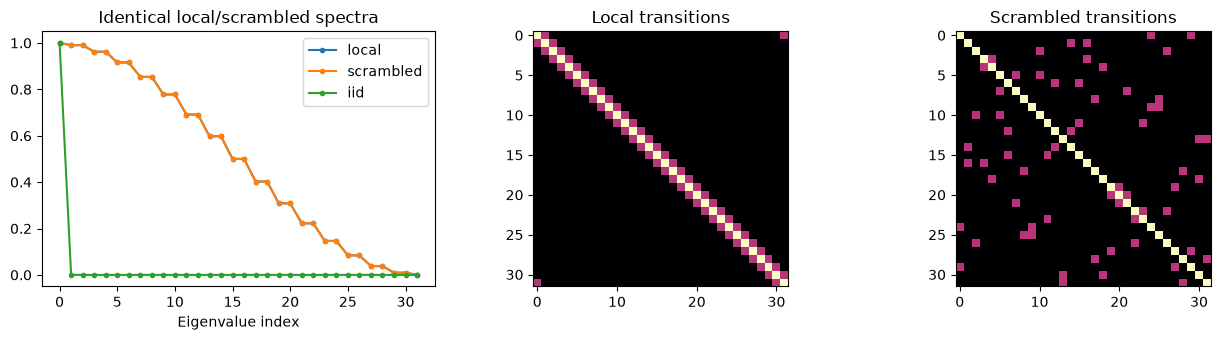

Population spectral subspace control passed; this is an established oracle fact, not a neural-training result.


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for name, transition in family.items():
    axes[0].plot(np.linalg.eigvalsh(transition)[::-1], '.-', label=name)
axes[0].set(title='Identical local/scrambled spectra', xlabel='Eigenvalue index')
axes[0].legend()
axes[1].imshow(family['local'], cmap='magma'); axes[1].set_title('Local transitions')
axes[2].imshow(family['scrambled'], cmap='magma'); axes[2].set_title('Scrambled transitions')
fig.tight_layout(); fig.savefig(OUTPUT_DIR / 'controls.png', dpi=150)
plt.show()
h_local, gap = spectral_embedding(family['local'], DIM)
h_scrambled, _ = spectral_embedding(family['scrambled'], DIM)
np.testing.assert_allclose(h_scrambled @ h_scrambled.T, (h_local @ h_local.T)[np.ix_(permutation, permutation)], atol=1e-9)
print('Population spectral subspace control passed; this is an established oracle fact, not a neural-training result.')

## Coordinate-change control and metric sanity checks
If both the transition matrix **and** both sensor tables are relabeled consistently, the generated observations are unchanged. This is a pure coordinate change and is not the main intervention.

Orthogonal transformations should yield perfect geometric alignment, whereas an invertible anisotropic scaling can retain all information without preserving CKA or Procrustes geometry. Constant embeddings must not be reported as perfect alignment.

In [5]:
pairs = sample_pairs(family['local'], 512, SEED + 100)
inverse = np.argsort(permutation)
for table in (table_a, table_b):
    np.testing.assert_array_equal(table[pairs], table[permutation][inverse[pairs]])
rng = np.random.default_rng(SEED)
cal, test = rng.normal(size=(256, DIM)), rng.normal(size=(256, DIM))
rotation, _ = np.linalg.qr(rng.normal(size=(DIM, DIM)))
warp = np.diag(np.geomspace(1, 10, DIM))
checks = pd.DataFrame([
    {'case': 'orthogonal', 'cka': linear_cka(test, test @ rotation), 'procrustes_error': procrustes_test_error(cal, cal @ rotation, test, test @ rotation)},
    {'case': 'invertible anisotropic', 'cka': linear_cka(test, test @ warp), 'procrustes_error': procrustes_test_error(cal, cal @ warp, test, test @ warp)},
    {'case': 'constant', 'cka': linear_cka(np.ones_like(test), np.ones_like(test)), 'procrustes_error': float('nan')}
])
assert checks.iloc[0]['cka'] > 1 - 1e-10
assert checks.iloc[0]['procrustes_error'] < 1e-15
assert effective_rank(np.ones_like(test)) == 0
checks.to_csv(OUTPUT_DIR / 'metric_checks.csv', index=False)
display(checks)

,case,cka,procrustes_error
0,orthogonal,1.000000,3.448554e-31
1,invertible anisotropic,0.633207,4.129760e-01
2,constant,NaN,NaN


## Interpretation and export
These checks verify the manipulation and measurement conventions only. Local and scrambled conditions have the same ideal spectral alignment opportunity under injective noiseless channels; any finite-network difference must be interpreted relative to approximation, optimization, sampling, and observation noise. IID has no unique preferred nonconstant eigenspace. Copy the archive to durable storage before ending a cloud session.

In [6]:
import shutil
archive = shutil.make_archive(str(OUTPUT_DIR), 'zip', OUTPUT_DIR)
print('Saved archive:', archive)
from IPython.display import FileLink
display(FileLink(archive))

Saved archive: c:\Users\z005abpj\Desktop\The-Role-of-Dynamical-Structure-in-Cross-Modal-Representation-Learning\outputs\01_control_audit.zip


c:\Users\z005abpj\Desktop\The-Role-of-Dynamical-Structure-in-Cross-Modal-Representation-Learning\outputs\01_control_audit.zip